# Telecom Customer Churn Prediction
## Notebook 02: Predictive Modeling, Imbalance Handling & Evaluation

### Objectives
1. **Preprocess and encode** customer features for machine learning algorithms.
2. Establish a **Baseline Logistic Regression** model.
3. Address severe **class imbalance (~26% churners)** using cost-sensitive class weighting and decision threshold tuning to maximize **Recall**.
4. Train an optimized **XGBoost Classifier** with `scale_pos_weight`.
5. Compare models across **ROC-AUC, Recall, Precision, and F1 Score**.
6. Serialize the champion model, scaler, and feature schemas for deployment.

### 1. Data Ingestion & Data Cleaning

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import joblib

# Load raw dataset
df = pd.read_csv("../data/raw/telecom_churn.csv")

# Handle missing values
df['SeniorCitizen'] = df['SeniorCitizen'].fillna(df['SeniorCitizen'].mode()[0])
df = df.dropna(subset=['tenure'])
df['TotalCharges'] = pd.to_numeric(df['TotalCharges'], errors='coerce')
df['TotalCharges'] = df['TotalCharges'].fillna(df['MonthlyCharges'] * df['tenure'])

# Map target variable
df['Churn'] = df['Churn'].map({'Yes': 1, 'No': 0})

# Strip whitespace from categorical string columns
for col in df.select_dtypes(include='object').columns:
    df[col] = df[col].str.strip()

# Save cleaned dataset
df.to_csv("../data/processed/telecom_clean.csv", index=False)
print("Cleaned dataset saved. Shape:", df.shape)

Cleaned dataset saved. Shape: (6896, 21)


### 2. Feature Engineering & One-Hot Encoding
Drop customer identifiers (`customerID`) and convert categorical columns using dummy variables (`drop_first=True` to prevent multicollinearity).

In [2]:
# Drop customer ID
df_features = df.drop('customerID', axis=1)

# One-hot encode categorical features
df_encoded = pd.get_dummies(df_features, drop_first=True)

X = df_encoded.drop('Churn', axis=1)
y = df_encoded['Churn']

print(f"Feature matrix shape: {X.shape}")
print(f"Target distribution: \n{y.value_counts(normalize=True)}")

Feature matrix shape: (6896, 30)
Target distribution: 
Churn
0    0.740574
1    0.259426
Name: proportion, dtype: float64


### 3. Stratified Train-Test Split & Feature Normalization
Using an 80/20 stratified split to preserve the 26.5% churn ratio in both training and test sets. Numerical features are normalized via `StandardScaler` fitted strictly on the training partition.

In [3]:
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler

X_train, X_test, y_train, y_test = train_test_split(
    X, y,
    test_size=0.2,
    random_state=42,
    stratify=y
)

numerical_cols = ['tenure', 'MonthlyCharges', 'TotalCharges']
scaler = StandardScaler()

# Scale numerical features (fit on train, transform both)
X_train_scaled = X_train.copy()
X_test_scaled = X_test.copy()

X_train_scaled[numerical_cols] = scaler.fit_transform(X_train[numerical_cols])
X_test_scaled[numerical_cols] = scaler.transform(X_test[numerical_cols])

print(f"Train set shape: {X_train_scaled.shape}, Test set shape: {X_test_scaled.shape}")

Train set shape: (5516, 30), Test set shape: (1380, 30)


### 4. Baseline Model: Standard Logistic Regression
A standard linear baseline without class weighting or threshold tuning.

In [4]:
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score, roc_auc_score, classification_report

model_base = LogisticRegression(max_iter=1000, random_state=42)
model_base.fit(X_train_scaled, y_train)

y_pred_base = model_base.predict(X_test_scaled)
y_proba_base = model_base.predict_proba(X_test_scaled)[:, 1]

print("--- Baseline Logistic Regression ---")
print("Accuracy: ", accuracy_score(y_test, y_pred_base))
print("Precision:", precision_score(y_test, y_pred_base))
print("Recall:   ", recall_score(y_test, y_pred_base))
print("F1 Score: ", f1_score(y_test, y_pred_base))
print("ROC-AUC:  ", roc_auc_score(y_test, y_proba_base))

--- Baseline Logistic Regression ---
Accuracy:  0.8094202898550724
Precision: 0.6666666666666666
Recall:    0.5307262569832403
F1 Score:  0.5909797822706065
ROC-AUC:   0.8400865320491095


### 5. Imbalance Handling: Cost-Weighted Logistic Regression & Threshold Tuning
By setting `class_weight='balanced'`, minority churn instances receive higher penalization during loss computation. We also evaluate tuning the classification threshold to further improve recall.

In [5]:
model_weighted = LogisticRegression(
    max_iter=1000,
    random_state=42,
    class_weight='balanced'
)
model_weighted.fit(X_train_scaled, y_train)

y_pred_w = model_weighted.predict(X_test_scaled)
y_proba_w = model_weighted.predict_proba(X_test_scaled)[:, 1]

print("--- Balanced Class-Weighted Logistic Regression ---")
print("Accuracy: ", accuracy_score(y_test, y_pred_w))
print("Precision:", precision_score(y_test, y_pred_w))
print("Recall:   ", recall_score(y_test, y_pred_w))
print("F1 Score: ", f1_score(y_test, y_pred_w))
print("ROC-AUC:  ", roc_auc_score(y_test, y_proba_w))

# Threshold tuning experiment at 0.35
threshold = 0.35
y_pred_custom = (y_proba_w >= threshold).astype(int)
print(f"\n--- Tuned Threshold (>= {threshold}) ---")
print("Precision:", precision_score(y_test, y_pred_custom))
print("Recall:   ", recall_score(y_test, y_pred_custom))
print("F1 Score: ", f1_score(y_test, y_pred_custom))

--- Balanced Class-Weighted Logistic Regression ---
Accuracy:  0.7326086956521739
Precision: 0.49023090586145646
Recall:    0.770949720670391
F1 Score:  0.5993485342019544
ROC-AUC:   0.8385860236801539

--- Tuned Threshold (>= 0.35) ---
Precision: 0.42570281124497994
Recall:    0.888268156424581
F1 Score:  0.5755656108597285


### 6. Advanced Non-Linear Model: XGBoost Classifier
We deploy extreme gradient boosting (`XGBClassifier`) with `scale_pos_weight` set to the negative-to-positive ratio to capture non-linear relationships and high-order feature interactions.

In [6]:
from xgboost import XGBClassifier

neg = sum(y_train == 0)
pos = sum(y_train == 1)
scale_pos_weight = neg / pos
print(f"Computed scale_pos_weight: {scale_pos_weight:.2f}")

xgb_model = XGBClassifier(
    n_estimators=300,
    learning_rate=0.05,
    max_depth=4,
    random_state=42,
    scale_pos_weight=scale_pos_weight,
    eval_metric='logloss'
)

xgb_model.fit(X_train_scaled, y_train)

y_pred_xgb = xgb_model.predict(X_test_scaled)
y_proba_xgb = xgb_model.predict_proba(X_test_scaled)[:, 1]

print("--- Final Champion Model: XGBoost ---")
print("Accuracy: ", accuracy_score(y_test, y_pred_xgb))
print("Precision:", precision_score(y_test, y_pred_xgb))
print("Recall:   ", recall_score(y_test, y_pred_xgb))
print("F1 Score: ", f1_score(y_test, y_pred_xgb))
print("ROC-AUC:  ", roc_auc_score(y_test, y_proba_xgb))

Computed scale_pos_weight: 2.85


--- Final Champion Model: XGBoost ---
Accuracy:  0.7536231884057971
Precision: 0.5171102661596958
Recall:    0.7597765363128491
F1 Score:  0.6153846153846154
ROC-AUC:   0.8380366572281319


### 7. Model Performance Comparison & Visualization

,Recall,Precision,F1,ROC-AUC
Baseline Logistic,0.530726,0.666667,0.590980,0.840087
Logistic Weighted,0.770950,0.490231,0.599349,0.838586
XGBoost,0.759777,0.517110,0.615385,0.838037


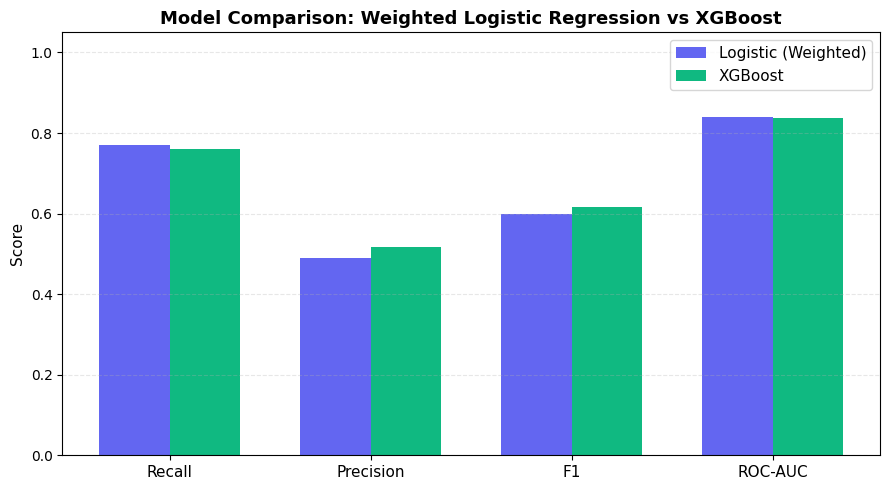

In [7]:
results = {
    'Baseline Logistic': {
        'Recall': recall_score(y_test, y_pred_base),
        'Precision': precision_score(y_test, y_pred_base),
        'F1': f1_score(y_test, y_pred_base),
        'ROC-AUC': roc_auc_score(y_test, y_proba_base)
    },
    'Logistic Weighted': {
        'Recall': recall_score(y_test, y_pred_w),
        'Precision': precision_score(y_test, y_pred_w),
        'F1': f1_score(y_test, y_pred_w),
        'ROC-AUC': roc_auc_score(y_test, y_proba_w)
    },
    'XGBoost': {
        'Recall': recall_score(y_test, y_pred_xgb),
        'Precision': precision_score(y_test, y_pred_xgb),
        'F1': f1_score(y_test, y_pred_xgb),
        'ROC-AUC': roc_auc_score(y_test, y_proba_xgb)
    }
}

results_df = pd.DataFrame(results).T
display(results_df)

metrics = ['Recall', 'Precision', 'F1', 'ROC-AUC']
log_values = [results['Logistic Weighted'][m] for m in metrics]
xgb_values = [results['XGBoost'][m] for m in metrics]

x = np.arange(len(metrics))
width = 0.35

plt.figure(figsize=(9, 5))
plt.bar(x - width/2, log_values, width, label='Logistic (Weighted)', color='#6366f1')
plt.bar(x + width/2, xgb_values, width, label='XGBoost', color='#10b981')

plt.xticks(x, metrics, fontsize=11)
plt.ylabel("Score", fontsize=11)
plt.title("Model Comparison: Weighted Logistic Regression vs XGBoost", fontsize=13, fontweight='bold')
plt.legend(fontsize=11)
plt.ylim(0, 1.05)
plt.grid(axis='y', linestyle='--', alpha=0.3)
plt.tight_layout()
plt.show()

### 8. Production Artifact Persistence
Serialize the fitted `scaler`, `xgb_model`, and `model_columns` for real-time inference in the Streamlit application.

In [8]:
import joblib

# Persist artifacts in project root
joblib.dump(scaler, "../scaler.pkl")
joblib.dump(xgb_model, "../xgb_model.pkl")
joblib.dump(X_train.columns.tolist(), "../model_columns.pkl")

# Also save locally in working directory for safety
joblib.dump(scaler, "scaler.pkl")
joblib.dump(xgb_model, "xgb_model.pkl")
joblib.dump(X_train.columns.tolist(), "model_columns.pkl")

print("Model artifacts (scaler.pkl, xgb_model.pkl, model_columns.pkl) serialized successfully!")

Model artifacts (scaler.pkl, xgb_model.pkl, model_columns.pkl) serialized successfully!
